In [3]:
!pip install 'powerlaw'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 567.8/567.8 kB 32.0 MB/s eta 0:00:00


In [4]:
import bmll2 as b2
from bmll2 import reference, Security, NormalisedSecurity, SparkHelper, get_market_data, get_market_data_range, VenueMarketError, get_market_tables, save_spark_dataframe, load_spark_dataframe

b2.get_file('modules/metaorder.py')
b2.get_file('modules/LMF.py')
b2.get_file('modules/calibration.py')

import metaorder as metaorder
import LMF as LMF
import calibration as calibration

import random
import math
import pandas as pd
import polars as pl
import numpy as np
from pandas import StringDtype
from datetime import timedelta

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.ticker import LogFormatterSciNotation

from statsmodels.sandbox.stats.runs import runstest_1samp
import powerlaw
import itertools
import pylab
import scipy.stats
import scipy.fft
from scipy.optimize import curve_fit
from sklearn.model_selection import ParameterGrid

from statsmodels.tsa.stattools import acf
from scipy.stats import t

from typing import Literal

# Note

In order to produce the market impact curve and trade sign imbalance table, the metaorders of the entire market need to be generated using the corresponding **config** and **grouped** user-configurable settings. This can be done using `calibration_results.ipynb`. 

# Synthetic metaorder configuration settings

## Fixed settings

The following settings define the market and trader participation assumptions used throughout the study and should not be modified.

- **trader_participation_distribution**: Distribution of trader participation rates. Fixed as `'power'`, corresponding to a power-law distribution.
- **exchange**: Exchange from which the data were obtained. Fixed as `'XJSE'`.

## User-configurable settings

The following settings control the construction of synthetic metaorders.

- **config**: Objective function used to select the optimal synthetic metaorder configuration.
    - `'metaorder'`: minimises \( e_M \)
    - `'LMF'`: minimises \( e_{LMF} \)
    - `'combined'`: minimises \( e_{combo} \)
- **grouped**: If `True`, the parameters \(N\) and \(\delta\) are constrained to be identical across all years. If `False`, they are estimated separately for each year.

In [5]:
trader_participation_distribution = 'power'
exchange                          = 'XJSE'
config                            = 'combined'
estimation_method                 = 'PSD'
grouped                           = False

In [6]:
if (grouped == True):
    flag = 'grouped'
else:
    flag = 'ungrouped'

files = b2.list_files(path = f'data/metaorders/{exchange}/calibrated/{trader_participation_distribution}/{config}')

for f in files:
    b2.get_file(f'data/metaorders/{exchange}/calibrated/{trader_participation_distribution}/{config}/{f}')
    
metaorder_data = pl.scan_parquet(f'*_XJSE_power_{config}_{flag}_metaorder_data_calibrated.parquet').collect()

In [17]:
b2.create_folder('figures_2', ensure_exists = True)
b2.create_folder('figures_2/impact_curves', ensure_exists = True)
b2.create_folder(f'figures_2/impact_curves/{exchange}', ensure_exists = True) 
b2.create_folder(f'figures_2/impact_curves/{exchange}/calibrated', ensure_exists = True) 
b2.create_folder(f'figures_2/impact_curves/{exchange}/calibrated/{config}', ensure_exists = True) 

Y: 0.461 \pm 0.004
exponent: 0.398 \pm 0.003
Market & $0.461 \pm 0.004$ & $0.398 \pm 0.003$


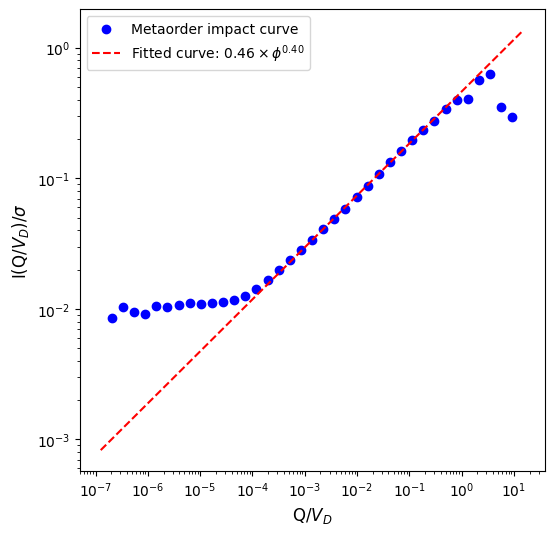

In [18]:
n_intervals = 40

df = metaorder_data.with_columns((pl.col('volume traded') / pl.col('20 AD volume')).alias('x_meta'),
                            (pl.col('metaorder impact') / pl.col('20 AD volatility')).fill_nan(None).alias('y_meta'))

x_min = df.select(pl.col('x_meta').min()).item()
x_max = df.select(pl.col('x_meta').max()).item()

bins = np.logspace(np.log10(x_min), np.log10(x_max), n_intervals)
df   = df.with_columns([pl.Series('bin', np.digitize(df['x_meta'].to_numpy(), bins) - 1)])

all_bins = pl.DataFrame({'bin': np.arange(len(bins) - 1)})
binned   = df.group_by('bin').agg(pl.col('y_meta').mean().alias('y_mean')).sort('bin')
binned   = all_bins.join(binned, on = 'bin', how = 'left').sort('bin')

bin_centers = (bins[:-1] + bins[1:]) / 2
binned      = binned.with_columns(x_center = bin_centers)

alpha  = 0.5
binned = binned.with_columns((alpha * pl.col('x_center').sqrt()).alias('sqrt_law'))

i, j, exp_est, r_2 = calibration.select_fitting_range(binned['x_center'], binned['y_mean'], min_points = 15)

def sql_model(x, exp, Y):
    return Y * x ** exp
    
y = np.array(binned['y_mean'][i:j])
x = np.array(binned['x_center'][i:j])

mask       = (x > 0) & np.isfinite(y)
x_fit      = x[mask]
impact_fit = y[mask]

if len(x_fit) < 10 or len(impact_fit) < 10:
    print('error')
            
try:
    params, covariance = curve_fit(sql_model, x_fit, impact_fit, p0 = [0.5, 0.5], maxfev = 100000)

except RuntimeError:
    print('error')

exp_est = params[0]
Y_est   = params[1]

fitted_curve = sql_model(x, exp_est, Y_est)

n   = len(x_fit)
p   = len(params)          # number of parameters (2 here)
dof = n - p                # degrees of freedom

alpha = 0.05               # 95% CI
tval  = t.ppf(1 - alpha / 2, dof)
se    = np.sqrt(np.diag(covariance))
interval_half_widths = tval * se[0], tval * se[1]

print(f'Y: {Y_est:.3f} \\pm {se[1]:.3f}')
print(f'exponent: {exp_est:.3f} \\pm {se[0]:.3f}')
print(f'Market & ${Y_est:.3f} \\pm {se[1]:.3f}$ & ${exp_est:.3f} \\pm {se[0]:.3f}$')

fig, ax = plt.subplots(figsize = (6, 6))

ax.set_xscale('log')
ax.set_yscale('log')

ax.scatter(binned['x_center'], binned['y_mean'], marker = 'o', color = 'blue', label = 'Metaorder impact curve')
#ax.plot(binned['x_center'], binned['sqrt_law'], linestyle = '--', color = 'red', label = r'0.5 $\times \sqrt{Q/V_{D}}$')
ax.plot(binned['x_center'], Y_est * binned['x_center'] ** exp_est, color = 'red', linestyle = '--', label = rf'Fitted curve: ${Y_est:.2f} \times \phi^{{{exp_est:.2f}}}$')

ax.set_xlabel(r'Q/$V_{D}$', fontsize = 12)
ax.set_ylabel(r'I(Q/$V_{D}$)/$\sigma$', fontsize = 12)

ax.xaxis.set_major_formatter(LogFormatterSciNotation(labelOnlyBase = False))
ax.yaxis.set_major_formatter(LogFormatterSciNotation(labelOnlyBase = False))

plt.legend()

plt.savefig(f'{exchange}_{config}_{flag}_calibrated_impact_curve.pdf')
b2.put_file(f'{exchange}_{config}_{flag}_calibrated_impact_curve.pdf', f'figures_2/impact_curves/{exchange}/calibrated/{config}')
b2.get_file(f'figures_2/impact_curves/{exchange}/calibrated/{config}/{exchange}_{config}_{flag}_calibrated_impact_curve.pdf')

plt.show()

# Checking for possible trade sign imbalance

This table checks for any trade sign imbalance that may produce the observed plateau for metaorders with $Q/V_D \leq 10^{-4}$. It also shows the average $Q/V_D$ for the metaorders with $Q/V_D \leq 10^{-4}$ as well as some other metrics which may be useful.

In [19]:

df = metaorder_data.with_columns((pl.col('volume traded') / pl.col('20 AD volume')).alias('x_meta'))

bias_table = df.group_by('trade sign').agg([pl.len().alias('count'),
                              (pl.len() / len(df)).alias(f'% of data'),
                              pl.col('x_meta').mean().alias(f'ave $Q/V_D$'),
                              ((pl.col('x_meta') <= 0.0001).sum() / len(df)).alias(f'% of data $\\leq 10^{{-2}}$'),
                              pl.col('x_meta').filter(pl.col('x_meta') <= 0.0001).mean().alias(f'ave $Q/V_D \\leq 10^{{-2}}')])
print(bias_table.to_pandas().to_latex(index = False, float_format = '%.6f'))

\begin{tabular}{rrrrrr}
\toprule
trade sign & count & % of data & ave $Q/V_D$ & % of data $\leq 10^{-2}$ & ave $Q/V_D \leq 10^{-2} \\
\midrule
1 & 25592264 & 0.500445 & 0.001429 & 0.062246 & 0.000054 \\
-1 & 25546738 & 0.499555 & 0.001446 & 0.061479 & 0.000055 \\
\bottomrule
\end{tabular}

